# PidginMed-ASR — Whisper-large-v3 Reviewer-Updated Pipeline

This notebook follows the original working Whisper pipeline and adds only the reviewer-requested controls:

- fixed speaker-independent split saved to a reusable manifest;
- English-prompt versus no-language-prompt zero-shot ablation;
- model-specific hyperparameter tuning with validation-based checkpoint selection;
- early stopping, training progress, and loss/WER/CER per epoch;
- identical `sample_id` fields for later cross-model alignment;
- full-test and medical-bearing-subset evaluation;
- optional validated Nigerian Pidgin medical lexicon;
- speaker-level and code-switch-stratified results;
- compute/runtime reporting and reproducible seeds.

Run the notebook from top to bottom in Google Colab.


In [1]:
%pip install -q -U transformers datasets evaluate jiwer accelerate soundfile librosa scikit-learn tqdm

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 57.4/57.4 kB 6.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 12.6/12.6 MB 122.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 604.4/604.4 kB 46.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 84.1/84.1 kB 7.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 294.6/294.6 kB 37.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 9.1/9.1 MB 126.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 80.2/80.2 kB 9.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 53.9/53.9 MB 43.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.2/3.2 MB 123.6 MB/s eta 0:00:00
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
ipython 7.34.0 requires jedi>=0.16, which is not installed.
cudf-cu13 26.6.0 requires pyarrow<24,>=19.0.0, but y

In [2]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
import torch

print(torch.cuda.get_device_name(0))
print(
    f"GPU Memory: "
    f"{torch.cuda.get_device_properties(0).total_memory / 1024**3:.1f} GB"
)

NVIDIA RTX PRO 6000 Blackwell Server Edition
GPU Memory: 95.0 GB


## 1. Configuration

In [3]:
import os
import re
import ast
import gc
import json
import time
import random
import hashlib
from pathlib import Path
from dataclasses import dataclass, asdict
from typing import Any, Dict, List, Optional, Sequence, Union
import numpy as np
import pandas as pd
import torch
import evaluate
import matplotlib.pyplot as plt

from datasets import Dataset, Audio, load_from_disk
from jiwer import wer, cer
from sklearn.model_selection import train_test_split
from tqdm.auto import tqdm

from transformers import (
    WhisperProcessor,
    WhisperForConditionalGeneration,
    Seq2SeqTrainingArguments,
    Seq2SeqTrainer,
    EarlyStoppingCallback,
    TrainerCallback,
    set_seed,
)

In [4]:
BASE = Path("/content/drive/MyDrive/Brock_University/pidgindataset2026October/")
METADATA_PATH = BASE / "root/Metadata.csv"
OUTPUT_ROOT = BASE / "PidginMed-ASR" / "whisper"
SPLIT_MANIFEST_PATH = BASE / "PidginMed-ASR/" / "shared_split_manifest.csv"

In [5]:
# metadata="/content/drive/MyDrive/Brock_University/pidgin_dataset/Final_Dataset/root/metadata_version3.0.csv",
# audio_root="/content/drive/MyDrive/Brock_University/pidgin_dataset/Final_Dataset/",
# output_dir="/content/drive/MyDrive/PidginMed-ASR/reviewer_revision_outputs/whisper",
# split_manifest="/content/drive/MyDrive/PidginMed-ASR/reviewer_revision_outputs/shared_split_manifest.csv",
# -----------------------------
# USER PATHS
# -----------------------------


# Optional manually validated bilingual/Pidgin medical lexicon.
# Required columns when supplied:
#   source_term, pidgin_variant
VALIDATED_LEXICON_PATH = None

MODEL_NAME = "openai/whisper-large-v3"
SEED = 42
TEST_SIZE = 0.20
VAL_SIZE_WITHIN_REMAINING = 0.15

ZERO_SHOT_PROMPT_MODES = ["english", "none"]
ZERO_SHOT_BATCH_SIZE = 1

# Reviewer-requested model-specific tuning.
# Start with these three controlled trials. Add more only if compute permits.
HYPERPARAMETER_TRIALS = [
    {"learning_rate": 1e-5, "epochs": 5,  "weight_decay": 0.00},
]

PER_DEVICE_TRAIN_BATCH_SIZE = 16
PER_DEVICE_EVAL_BATCH_SIZE = 16
GRADIENT_ACCUMULATION_STEPS = 2  # Effective batch size = 16
EARLY_STOPPING_PATIENCE = 3
WARMUP_STEPS = 100
GENERATION_MAX_LENGTH = 250

# PER_DEVICE_TRAIN_BATCH_SIZE = 16
# PER_DEVICE_EVAL_BATCH_SIZE = 4
# GRADIENT_ACCUMULATION_STEPS = 4  # effective train batch size = 32
# EARLY_STOPPING_PATIENCE = 2
# WARMUP_STEPS = 200
# GENERATION_MAX_LENGTH = 300

RUN_ZERO_SHOT = True
RUN_HYPERPARAMETER_SEARCH = True
RUN_FINAL_EVALUATION = True

OUTPUT_ROOT.mkdir(parents=True, exist_ok=True)
SPLIT_MANIFEST_PATH.parent.mkdir(parents=True, exist_ok=True)

set_seed(SEED)
random.seed(SEED)
np.random.seed(SEED)

print("Torch:", torch.__version__)
print("CUDA available:", torch.cuda.is_available())
if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))
    print("GPU memory (GB):", round(torch.cuda.get_device_properties(0).total_memory / 1e9, 2))
print("Effective training batch size:",
      PER_DEVICE_TRAIN_BATCH_SIZE * GRADIENT_ACCUMULATION_STEPS)


Torch: 2.11.0+cu130
CUDA available: True
GPU: NVIDIA A100-SXM4-80GB
GPU memory (GB): 85.09
Effective training batch size: 32


In [6]:
df = pd.read_csv(METADATA_PATH)

In [ ]:
# output_path = BASE / "Metadata.csv"

# df.to_csv(output_path, index=False)

# print(f"Saved successfully to: {output_path}")
# print(f"Total samples saved: {len(df)}")

Saved successfully to: /content/drive/MyDrive/Brock_University/pidgindataset2026October/Metadata.csv
Total samples saved: 10218


## 2. Load and clean metadata

In [7]:
df.columns = df.columns.str.lower().str.strip()

required_columns = ["audio_path", "pidgin_transcription", "english_translation", "speaker_id"]
missing = [c for c in required_columns if c not in df.columns]
if missing:
    raise ValueError(f"Missing required metadata columns: {missing}")

df = df.dropna(subset=required_columns).copy()

if "audio_length" in df.columns:
    df["audio_length"] = (
        df["audio_length"]
        .astype(str)
        .str.replace("secs", "", regex=False)
        .str.strip()
    )
    df["audio_length"] = pd.to_numeric(df["audio_length"], errors="coerce")
    df = df[df["audio_length"] > 1].copy()

def normalize_text(text):
    text = str(text).lower()
    text = re.sub(r"[^a-zA-Z\s]", " ", text)
    text = re.sub(r"\s+", " ", text).strip()
    return text

def parse_medical_terms(value):
    if isinstance(value, list):
        terms = value
    elif pd.isna(value):
        terms = []
    elif isinstance(value, str):
        value = value.strip()
        if value in {"", "[]", "nan", "None", "null"}:
            terms = []
        else:
            try:
                terms = ast.literal_eval(value)
                if not isinstance(terms, list):
                    terms = [terms]
            except Exception:
                terms = [x.strip() for x in value.split(",") if x.strip()]
    else:
        terms = []

    cleaned = []
    seen = set()
    for term in terms:
        term = normalize_text(term)
        if term and term not in seen:
            cleaned.append(term)
            seen.add(term)
    return cleaned

if "medical_terms_pidgen" in df.columns:
    df["medical_terms_pidgen"] = df["medical_terms_pidgen"].apply(parse_medical_terms)
elif "medical_terms_clean" in df.columns:
    df["medical_terms_pidgen"] = df["medical_terms_clean"].apply(parse_medical_terms)
else:
    df["medical_terms_pidgen"] = [[] for _ in range(len(df))]

# Preserve the original working audio construction.
def resolve_audio_path(path_value):
    path_value = str(path_value)
    path = Path(path_value)
    if path.is_absolute():
        return str(path)
    return str(BASE / path_value)

df["audio"] = df["audio_path"].apply(resolve_audio_path)
df["text"] = df["pidgin_transcription"].astype(str)
df["reference"] = df["pidgin_transcription"].apply(normalize_text)

# Stable sample ID used by Whisper, Canary, and MedASR for strict alignment.
def make_sample_id(row):
    candidate_columns = ["sample_id", "utterance_id", "id", "file_id"]
    for col in candidate_columns:
        if col in row.index and pd.notna(row[col]) and str(row[col]).strip():
            return str(row[col]).strip()

    audio_name = Path(str(row["audio_path"])).name
    key = f"{audio_name}|{normalize_text(row['pidgin_transcription'])}"
    return hashlib.sha1(key.encode("utf-8")).hexdigest()[:20]

df["sample_id"] = df.apply(make_sample_id, axis=1)

if df["sample_id"].duplicated().any():
    duplicated = df.loc[df["sample_id"].duplicated(False), ["sample_id", "audio_path"]]
    raise ValueError(f"Duplicate sample IDs detected:\n{duplicated.head(20)}")

missing_audio = [p for p in df["audio"] if not Path(p).exists()]
print("Rows after cleaning:", len(df))
print("Unique speakers:", df["speaker_id"].nunique())
print("Missing audio files:", len(missing_audio))
if missing_audio:
    print("First missing paths:", missing_audio[:5])

df.head()

Rows after cleaning: 10218
Unique speakers: 21
Missing audio files: 0


,speaker_id,audio_path,pidgin_transcription,english_translation,medical_terms_english,medical_terms_pidgen,audio_length,sample_rate,num_channels,speech_rate,signal_to_noise_ratio,silence_ratio,audio,file_exists,text,reference,sample_id
0,Speaker_1,root/audio/Speaker_1/Speaker1-1.wav,e depend on your effort how you take dey do ex...,it all depends on your efforts regarding regul...,"['care', 'knee', 'walk', 'two days', 'one to t...","[exercise, everytime, after two day, normally,...",19.04,16000.0,1.0,2.678378,54.947548,0.319377,/content/drive/MyDrive/Brock_University/pidgin...,True,e depend on your effort how you take dey do ex...,e depend on your effort how you take dey do ex...,6a840a4ad1fd60283227
1,Speaker_1,root/audio/Speaker_1/Speaker1-2.wav,my daughter make four years two nights ago she...,my daughter is four years old two nights ago s...,"['daughter', 'four years old', 'vomited', 'sor...","[daughter, wake up, vomited, pain, hot, parace...",34.48,16000.0,1.0,2.580879,53.953575,0.334655,/content/drive/MyDrive/Brock_University/pidgin...,True,my daughter make four years two nights ago she...,my daughter make four years two nights ago she...,fa777d58c8f323da62e2
2,Speaker_1,root/audio/Speaker_1/Speaker1-3.wav,hi dis na retention cyst e go need excise for ...,hi this is definitely a retention cyst it need...,"['retention cyst', 'mass', 'histopathological ...","[reasons, removed, important part of the body,...",21.97,16000.0,1.0,2.321869,57.647476,0.335672,/content/drive/MyDrive/Brock_University/pidgin...,True,hi dis na retention cyst e go need excise for ...,hi dis na retention cyst e go need excise for ...,01fceaa9e74b77698df4
3,Speaker_1,root/audio/Speaker_1/Speaker1-4.wav,i be thirty one years woman and i get blod clo...,i am a thirty one year old woman with a blood ...,"['thirty one year old woman', 'head injury', '...","[thirty one years woman, not, head injury, inj...",34.61,16000.0,1.0,2.571562,49.890247,0.308394,/content/drive/MyDrive/Brock_University/pidgin...,True,i be thirty one years woman and i get blod clo...,i be thirty one years woman and i get blod clo...,3d812380dee30f23b366
4,Speaker_1,root/audio/Speaker_1/Speaker1-5.wav,i be forty five years old man my platelet coun...,i am forty five years old male my platelet cou...,"['forty five years old male', 'platelet count'...","[forty five years old man, platelet count, thi...",42.63,16000.0,1.0,2.040783,50.834831,0.307166,/content/drive/MyDrive/Brock_University/pidgin...,True,i be forty five years old man my platelet coun...,i be forty five years old man my platelet coun...,ac3bdc92665cb5600166


## 3. Fixed speaker-independent split and reusable manifest

In [8]:
def create_or_load_speaker_split(
    frame,
    manifest_path,
    rebuild_if_incomplete=True,
):
    frame = frame.copy()
    manifest_path = Path(manifest_path)

    def create_new_manifest(current_frame):
        speakers = sorted(
            current_frame["speaker_id"]
            .astype(str)
            .unique()
            .tolist()
        )

        train_speakers, test_speakers = train_test_split(
            speakers,
            test_size=TEST_SIZE,
            random_state=42,
        )

        train_speakers, val_speakers = train_test_split(
            train_speakers,
            test_size=VAL_SIZE_WITHIN_REMAINING,
            random_state=42,
        )

        split_map = {}
        split_map.update({
            speaker: "train"
            for speaker in train_speakers
        })
        split_map.update({
            speaker: "validation"
            for speaker in val_speakers
        })
        split_map.update({
            speaker: "test"
            for speaker in test_speakers
        })

        current_frame["split"] = (
            current_frame["speaker_id"]
            .astype(str)
            .map(split_map)
        )

        if current_frame["split"].isna().any():
            missing_speakers = (
                current_frame.loc[
                    current_frame["split"].isna(),
                    "speaker_id",
                ]
                .astype(str)
                .unique()
                .tolist()
            )
            raise ValueError(
                "Could not assign a split to speakers: "
                f"{missing_speakers}"
            )

        manifest_columns = [
            "sample_id",
            "speaker_id",
            "split",
            "audio_path",
            "pidgin_transcription",
            "english_translation",
        ]

        optional_columns = [
            "audio_length",
            "code_switch_category",
            "cmi",
            "english_ratio",
            "pidgin_ratio",
        ]

        manifest_columns += [
            column
            for column in optional_columns
            if column in current_frame.columns
        ]

        manifest = current_frame[manifest_columns].copy()

        manifest_path.parent.mkdir(
            parents=True,
            exist_ok=True,
        )

        manifest.to_csv(
            manifest_path,
            index=False,
        )

        print(
            "Created new shared split manifest:",
            manifest_path,
        )

        return current_frame, manifest

    if not manifest_path.exists():
        return create_new_manifest(frame)

    manifest = pd.read_csv(
        manifest_path,
        dtype={
            "sample_id": str,
            "speaker_id": str,
        },
    )

    required = {
        "sample_id",
        "split",
        "speaker_id",
    }

    if not required.issubset(manifest.columns):
        if rebuild_if_incomplete:
            print(
                "Existing manifest is missing required columns. "
                "Rebuilding it."
            )
            return create_new_manifest(frame)

        raise ValueError(
            f"Split manifest must contain {sorted(required)}"
        )

    frame["sample_id"] = frame["sample_id"].astype(str)
    frame["speaker_id"] = frame["speaker_id"].astype(str)

    manifest["sample_id"] = manifest["sample_id"].astype(str)
    manifest["speaker_id"] = manifest["speaker_id"].astype(str)

    current_ids = set(frame["sample_id"])
    manifest_ids = set(manifest["sample_id"])

    missing_from_manifest = current_ids - manifest_ids
    extra_in_manifest = manifest_ids - current_ids

    if missing_from_manifest:
        print(
            f"Manifest is missing "
            f"{len(missing_from_manifest)} current samples."
        )

        if rebuild_if_incomplete:
            backup_path = manifest_path.with_suffix(
                ".old.csv"
            )

            manifest.to_csv(
                backup_path,
                index=False,
            )

            print(
                "Saved old manifest backup to:",
                backup_path,
            )

            return create_new_manifest(frame)

        raise ValueError(
            "Some metadata samples are absent from the "
            f"existing split manifest. First examples: "
            f"{list(missing_from_manifest)[:10]}"
        )

    if extra_in_manifest:
        print(
            f"Manifest contains "
            f"{len(extra_in_manifest)} samples not present "
            "in the current metadata. They will be ignored."
        )

    merged = frame.merge(
        manifest[
            [
                "sample_id",
                "split",
                "speaker_id",
            ]
        ],
        on="sample_id",
        how="left",
        suffixes=("", "_manifest"),
        validate="one_to_one",
    )

    speaker_mismatch = (
        merged["speaker_id"].astype(str)
        != merged["speaker_id_manifest"].astype(str)
    )

    if speaker_mismatch.any():
        mismatched = merged.loc[
            speaker_mismatch,
            [
                "sample_id",
                "speaker_id",
                "speaker_id_manifest",
            ],
        ].head(10)

        raise ValueError(
            "Speaker IDs do not match the saved manifest:\n"
            f"{mismatched}"
        )

    merged = merged.drop(
        columns=["speaker_id_manifest"]
    )

    print(
        "Loaded existing shared split manifest:",
        manifest_path,
    )

    return merged, manifest

df, split_manifest = create_or_load_speaker_split(df, SPLIT_MANIFEST_PATH)

train_df = df[df["split"] == "train"].copy().reset_index(drop=True)
val_df = df[df["split"] == "validation"].copy().reset_index(drop=True)
test_df = df[df["split"] == "test"].copy().reset_index(drop=True)

# Leakage audit.
train_speakers = set(train_df["speaker_id"].astype(str))
val_speakers = set(val_df["speaker_id"].astype(str))
test_speakers = set(test_df["speaker_id"].astype(str))

assert train_speakers.isdisjoint(val_speakers)
assert train_speakers.isdisjoint(test_speakers)
assert val_speakers.isdisjoint(test_speakers)

split_summary = (
    df.groupby("split")
    .agg(samples=("sample_id", "count"),
         speakers=("speaker_id", "nunique"),
         hours=("audio_length", lambda x: x.sum() / 3600 if "audio_length" in df.columns else np.nan))
    .reset_index()
)
display(split_summary)

print("Train speakers:", sorted(train_speakers))
print("Validation speakers:", sorted(val_speakers))
print("Test speakers:", sorted(test_speakers))


Loaded existing shared split manifest: /content/drive/MyDrive/Brock_University/pidgindataset2026October/PidginMed-ASR/shared_split_manifest.csv


,split,samples,speakers,hours
0,test,2245,5,17.761647
1,train,6474,13,48.963886
2,validation,1499,3,12.255000


Train speakers: ['Speaker_11', 'Speaker_12', 'Speaker_13', 'Speaker_15', 'Speaker_16', 'Speaker_18', 'Speaker_19', 'Speaker_20', 'Speaker_3', 'Speaker_5', 'Speaker_7', 'Speaker_8', 'Speaker_9']
Validation speakers: ['Speaker_14', 'Speaker_2', 'Speaker_21']
Test speakers: ['Speaker_1', 'Speaker_10', 'Speaker_17', 'Speaker_4', 'Speaker_6']


## 4. Convert to Hugging Face datasets using the original working `Audio` pipeline

### PyArrow compatibility fix

The `audio` column is kept as a normal file-path string instead of being cast to `datasets.Audio`. Each recording is decoded lazily with `librosa` when used. This avoids the `large_string → struct` Arrow casting error while preserving the original Whisper processing sequence.


In [21]:
def dataframe_to_audio_dataset(frame):
    """
    Keep audio paths as plain strings instead of casting to datasets.Audio.

    This avoids:
        ArrowNotImplementedError:
        Unsupported cast from large_string to struct

    Audio is decoded lazily with librosa when each example is used.
    """
    work = frame.copy()
    work["audio"] = work["audio"].astype(str)

    return Dataset.from_pandas(
        work,
        preserve_index=False,
    )

def load_audio_16k(audio_value):
    """
    Accept either:
      - a file-path string, or
      - an already decoded audio dictionary.

    Returns a dictionary compatible with the original pipeline:
      {"array": np.ndarray, "sampling_rate": 16000}
    """
    import librosa

    if isinstance(audio_value, dict) and "array" in audio_value:
        array = np.asarray(audio_value["array"], dtype=np.float32)
        sampling_rate = int(audio_value.get("sampling_rate", 16000))

        if sampling_rate != 16000:
            array = librosa.resample(
                array,
                orig_sr=sampling_rate,
                target_sr=16000,
            )
            sampling_rate = 16000

        return {
            "array": array,
            "sampling_rate": sampling_rate,
        }

    audio_path = Path(str(audio_value))

    if not audio_path.exists():
        raise FileNotFoundError(f"Audio file not found: {audio_path}")

    array, sampling_rate = librosa.load(
        audio_path,
        sr=16000,
        mono=True,
    )

    return {
        "array": np.asarray(array, dtype=np.float32),
        "sampling_rate": int(sampling_rate),
    }

train_raw_ds = dataframe_to_audio_dataset(train_df)
val_raw_ds = dataframe_to_audio_dataset(val_df)
test_raw_ds = dataframe_to_audio_dataset(test_df)

test_raw_ds = test_raw_ds.filter(
    lambda x: (
        x["medical_terms_pidgen"] is not None
        and str(x["medical_terms_pidgen"]).strip().lower()
        not in ["", "[]", "nan", "none", "null"]
    )
)

print(train_raw_ds)
print(val_raw_ds)
print(test_raw_ds)


Filter:   0%|          | 0/2245 [00:00<?, ? examples/s]

Dataset({
    features: ['speaker_id', 'audio_path', 'pidgin_transcription', 'english_translation', 'medical_terms_english', 'medical_terms_pidgen', 'audio_length', 'sample_rate', 'num_channels', 'speech_rate', 'signal_to_noise_ratio', 'silence_ratio', 'audio', 'file_exists', 'text', 'reference', 'sample_id', 'split'],
    num_rows: 6474
})
Dataset({
    features: ['speaker_id', 'audio_path', 'pidgin_transcription', 'english_translation', 'medical_terms_english', 'medical_terms_pidgen', 'audio_length', 'sample_rate', 'num_channels', 'speech_rate', 'signal_to_noise_ratio', 'silence_ratio', 'audio', 'file_exists', 'text', 'reference', 'sample_id', 'split'],
    num_rows: 1499
})
Dataset({
    features: ['speaker_id', 'audio_path', 'pidgin_transcription', 'english_translation', 'medical_terms_english', 'medical_terms_pidgen', 'audio_length', 'sample_rate', 'num_channels', 'speech_rate', 'signal_to_noise_ratio', 'silence_ratio', 'audio', 'file_exists', 'text', 'reference', 'sample_id', 'sp

In [14]:
# Sanity check: the dataset stores a path string, and the loader returns decoded audio.
sample_audio_path = train_raw_ds[0]["audio"]
print("Stored audio value type:", type(sample_audio_path))
decoded_audio = load_audio_16k(sample_audio_path)
print("Decoded keys:", decoded_audio.keys())
print("Sampling rate:", decoded_audio["sampling_rate"])
print("Waveform length:", len(decoded_audio["array"]))

Stored audio value type: <class 'str'>
Decoded keys: dict_keys(['array', 'sampling_rate'])
Sampling rate: 16000
Waveform length: 607295


## 5. Load processor and zero-shot model

In [15]:
processor = WhisperProcessor.from_pretrained(
    MODEL_NAME,
    language="English",
    task="transcribe",
)

In [16]:
device = "cuda" if torch.cuda.is_available() else "cpu"

In [17]:
zero_shot_model = WhisperForConditionalGeneration.from_pretrained(MODEL_NAME)


zero_shot_model = zero_shot_model.to(device)
zero_shot_model.eval()

print("Using device:", device)

model.safetensors: reconstructing file:   0%|          |  0.00B / 3.09GB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/1259 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/3.90k [00:00<?, ?B/s]

Using device: cuda


## 6. Medical-term evaluation helpers

In [18]:
def load_validated_lexicon(path):
    if path is None:
        return {}
    path = Path(path)
    if not path.exists():
        raise FileNotFoundError(path)

    lexicon_df = pd.read_csv(path)
    required = {"source_term", "pidgin_variant"}
    if not required.issubset(lexicon_df.columns):
        raise ValueError(f"Validated lexicon requires columns: {sorted(required)}")

    mapping = {}
    for _, row in lexicon_df.iterrows():
        source = normalize_text(row["source_term"])
        variant = normalize_text(row["pidgin_variant"])
        if source and variant:
            mapping.setdefault(source, set()).add(variant)
    return mapping

VALIDATED_LEXICON = load_validated_lexicon(VALIDATED_LEXICON_PATH)

def expand_terms(terms):
    expanded = set()
    for term in parse_medical_terms(terms):
        expanded.add(term)
        expanded.update(VALIDATED_LEXICON.get(term, set()))
    return expanded

def phrase_present(text, phrase):
    text = f" {normalize_text(text)} "
    phrase = f" {normalize_text(phrase)} "
    return phrase in text

def reference_medical_terms(reference, terms):
    candidates = expand_terms(terms)
    return {term for term in candidates if phrase_present(reference, term)}

def predicted_medical_terms(prediction, terms):
    candidates = expand_terms(terms)
    return {term for term in candidates if phrase_present(prediction, term)}

def medical_term_metrics(predictions, references, medical_terms_list):
    tp = fp = fn = exact = 0
    evaluated_samples = 0

    for pred, ref, terms in zip(predictions, references, medical_terms_list):
        ref_terms = reference_medical_terms(ref, terms)
        pred_terms = predicted_medical_terms(pred, terms)

        # Only score a sample when at least one candidate is present in the
        # Nigerian Pidgin reference. This reduces English-source inventory noise.
        if not ref_terms:
            continue

        evaluated_samples += 1
        tp += len(ref_terms & pred_terms)
        fp += len(pred_terms - ref_terms)
        fn += len(ref_terms - pred_terms)
        exact += int(ref_terms == pred_terms)

    precision = tp / (tp + fp) if tp + fp else 0.0
    recall = tp / (tp + fn) if tp + fn else 0.0
    f1 = 2 * precision * recall / (precision + recall) if precision + recall else 0.0
    accuracy = exact / evaluated_samples if evaluated_samples else np.nan

    return {
        "medical_precision": precision,
        "medical_recall": recall,
        "medical_f1": f1,
        "medical_accuracy": accuracy,
        "medical_evaluated_samples": evaluated_samples,
        "medical_tp": tp,
        "medical_fp": fp,
        "medical_fn": fn,
    }

def medical_wer(predictions, references, medical_terms_list):
    ref_med_sentences = []
    pred_med_sentences = []

    for pred, ref, terms in zip(predictions, references, medical_terms_list):
        candidates = expand_terms(terms)
        ref_present = [term for term in candidates if phrase_present(ref, term)]

        if not ref_present:
            continue

        pred_present = [term for term in candidates if phrase_present(pred, term)]
        ref_med_sentences.append(" ".join(sorted(ref_present)))
        pred_med_sentences.append(" ".join(sorted(pred_present)))

    if not ref_med_sentences:
        return np.nan

    return wer(ref_med_sentences, pred_med_sentences)

def compute_overall_metrics(frame):
    refs = frame["reference"].tolist()
    preds = frame["prediction"].tolist()
    terms = frame["medical_terms_pidgen"].tolist()

    metrics = {
        "wer": wer(refs, preds),
        "cer": cer(refs, preds),
        "mwer": medical_wer(preds, refs, terms),
        "num_samples": len(frame),
    }
    metrics.update(medical_term_metrics(preds, refs, terms))
    return metrics


## 7. Reviewer-requested zero-shot language-prompt ablation

In [19]:
def configure_prompt(model, prompt_mode):
    if prompt_mode == "english":
        model.generation_config.language = "en"
        model.generation_config.task = "transcribe"
        return {
            "language": "en",
            "task": "transcribe",
        }

    if prompt_mode == "none":
        model.generation_config.language = None
        model.generation_config.task = "transcribe"
        model.generation_config.forced_decoder_ids = None
        return {
            "task": "transcribe",
        }

    raise ValueError(f"Unsupported prompt mode: {prompt_mode}")

def zero_shot_transcribe_dataset(dataset, source_frame, model, prompt_mode):
    generation_kwargs = configure_prompt(model, prompt_mode)
    rows = []

    progress = tqdm(
        range(len(dataset)),
        desc=f"Zero-shot Whisper ({prompt_mode})",
        unit="utterance",
        dynamic_ncols=True,
    )

    for i in progress:
        sample = dataset[i]
        audio = load_audio_16k(sample["audio"])

        inputs = processor(
            audio["array"],
            sampling_rate=audio["sampling_rate"],
            return_tensors="pt",
        ).input_features.to(device=device, dtype=model.dtype)

        with torch.no_grad():
            predicted_ids = model.generate(
                inputs,
                max_length=GENERATION_MAX_LENGTH,
                **generation_kwargs,
            )

        transcription = processor.batch_decode(
            predicted_ids,
            skip_special_tokens=True,
            clean_up_tokenization_spaces=False,
        )[0]

        source_row = source_frame.iloc[i].copy()
        result = source_row.to_dict()
        result["prediction"] = normalize_text(transcription)
        result["reference"] = normalize_text(source_row["pidgin_transcription"])
        result["prompt_mode"] = prompt_mode
        rows.append(result)

        if (i + 1) % 50 == 0:
            partial = pd.DataFrame(rows)
            progress.set_postfix(
                WER=f"{wer(partial.reference.tolist(), partial.prediction.tolist()):.4f}"
            )

    result_df = pd.DataFrame(rows)

    result_df["wer"] = result_df.apply(
        lambda row: wer(row["reference"], row["prediction"]), axis=1
    )
    result_df["cer"] = result_df.apply(
        lambda row: cer(row["reference"], row["prediction"]), axis=1
    )

    return result_df

zero_shot_summaries = []
zero_shot_outputs = {}

if RUN_ZERO_SHOT:
    for prompt_mode in ZERO_SHOT_PROMPT_MODES:
        prompt_dir = OUTPUT_ROOT / "zero_shot" / prompt_mode
        prompt_dir.mkdir(parents=True, exist_ok=True)

        prompt_predictions = zero_shot_transcribe_dataset(
            test_raw_ds,
            test_df,
            zero_shot_model,
            prompt_mode,
        )

        prompt_metrics = {
            "model": MODEL_NAME,
            "setting": "zero_shot",
            "prompt_mode": prompt_mode,
            **compute_overall_metrics(prompt_predictions),
        }

        prompt_predictions.to_csv(
            prompt_dir / "test_predictions.csv",
            index=False,
            encoding="utf-8-sig",
        )
        pd.DataFrame([prompt_metrics]).to_csv(
            prompt_dir / "overall_metrics.csv",
            index=False,
        )

        zero_shot_summaries.append(prompt_metrics)
        zero_shot_outputs[prompt_mode] = prompt_predictions

    zero_shot_summary_df = pd.DataFrame(zero_shot_summaries).sort_values("wer")
    zero_shot_summary_df.to_csv(
        OUTPUT_ROOT / "zero_shot_prompt_ablation.csv",
        index=False,
    )
    display(zero_shot_summary_df)


Zero-shot Whisper (english):   0%|          | 0/2223 [00:00<?, ?utterance/s]

[transformers] Passing `generation_config` together with generation-related arguments=({'suppress_tokens', 'begin_suppress_tokens'}) is deprecated and will be removed in future versions. Please pass either a `generation_config` object OR all generation parameters explicitly, but not both.


Zero-shot Whisper (none):   0%|          | 0/2223 [00:00<?, ?utterance/s]

,model,setting,prompt_mode,wer,cer,mwer,num_samples,medical_precision,medical_recall,medical_f1,medical_accuracy,medical_evaluated_samples,medical_tp,medical_fp,medical_fn
0,openai/whisper-large-v3,zero_shot,english,1.049238,0.801755,0.964229,2223,0.929108,0.050526,0.095840,0.005009,2196,865,66,16255
1,openai/whisper-large-v3,zero_shot,none,1.049506,0.802644,0.965550,2223,0.928414,0.049241,0.093521,0.003643,2196,843,65,16277


In [20]:
# Aggregated zero-shot test results
for prompt_mode, predictions_df in zero_shot_outputs.items():

    metrics = compute_overall_metrics(predictions_df)

    print(f"\nZero-shot Whisper ({prompt_mode})")
    print(f"Test Samples: {metrics['num_samples']}")
    print(f"WER:  {metrics['wer']:.4f}")
    print(f"CER:  {metrics['cer']:.4f}")
    print(f"MWER: {metrics['mwer']:.4f}")
    print(f"Medical F1: {metrics['medical_f1']:.4f}")


Zero-shot Whisper (english)
Test Samples: 2223
WER:  1.0492
CER:  0.8018
MWER: 0.9642
Medical F1: 0.0958

Zero-shot Whisper (none)
Test Samples: 2223
WER:  1.0495
CER:  0.8026
MWER: 0.9656
Medical F1: 0.0935


## 8. Prepare datasets for fine-tuning

In [ ]:
def prepare_dataset(batch):
    audio = load_audio_16k(batch["audio"])

    # Retain the original working feature-extraction approach.
    batch["input_features"] = processor.feature_extractor(
        audio["array"],
        sampling_rate=audio["sampling_rate"],
    ).input_features[0]

    batch["labels"] = processor.tokenizer(
        normalize_text(batch["pidgin_transcription"])
    ).input_ids

    return batch

cache_root = OUTPUT_ROOT / "processed_datasets"
train_proc_path = cache_root / "train"
val_proc_path = cache_root / "validation"
cache_root.mkdir(parents=True, exist_ok=True)

if train_proc_path.exists() and val_proc_path.exists():
    train_ds = load_from_disk(str(train_proc_path))
    val_ds = load_from_disk(str(val_proc_path))
    print("Loaded cached processed datasets.")
else:
    train_ds = train_raw_ds.map(
        prepare_dataset,
        remove_columns=train_raw_ds.column_names,
        desc="Preparing training audio",
    )
    val_ds = val_raw_ds.map(
        prepare_dataset,
        remove_columns=val_raw_ds.column_names,
        desc="Preparing validation audio",
    )

    train_ds.save_to_disk(str(train_proc_path))
    val_ds.save_to_disk(str(val_proc_path))
    print("Saved processed datasets.")

print(processor.batch_decode([train_ds[0]["labels"]], skip_special_tokens=False))


Loading dataset from disk:   0%|          | 0/20 [00:00<?, ?it/s]

[transformers] Ignoring clean_up_tokenization_spaces=True for BPE tokenizer WhisperTokenizer. The clean_up_tokenization post-processing step is designed for WordPiece tokenizers and is destructive for BPE (it strips spaces before punctuation). Set clean_up_tokenization_spaces=False to suppress this warning, or set clean_up_tokenization_spaces_for_bpe_even_though_it_will_corrupt_output=True to force cleanup anyway.


Loaded cached processed datasets.
['<|startoftranscript|><|en|><|transcribe|><|notimestamps|>my period neva come for like three weeks now i no carry belle i don do pregnancy test for house and for doctor office all say negative for like five days now my belle de pain me for dat right side near my ovary di pain no gree go dis na weekend and i no think say i fit wait till monday to go see doctor wetin i go do i dey fear well well abeg help me<|endoftext|>']


## 9. Data collator

In [ ]:
from dataclasses import dataclass
from typing import Any, Dict, List, Union

import torch

@dataclass
class DataCollatorSpeechSeq2SeqWithPadding:
    processor: Any
    decoder_start_token_id: int

    def __call__(
        self,
        features: List[Dict[str, Union[List[int], torch.Tensor]]],
    ) -> Dict[str, torch.Tensor]:

        input_features = [
            {"input_features": feature["input_features"]}
            for feature in features
        ]

        batch = self.processor.feature_extractor.pad(
            input_features,
            return_tensors="pt",
        )

        label_features = [
            {"input_ids": feature["labels"]}
            for feature in features
        ]

        labels_batch = self.processor.tokenizer.pad(
            label_features,
            return_tensors="pt",
        )

        labels = labels_batch["input_ids"].masked_fill(
            labels_batch.attention_mask.ne(1),
            -100,
        )

        if (
            labels.shape[1] > 0
            and (labels[:, 0] == self.decoder_start_token_id).all()
        ):
            labels = labels[:, 1:]

        batch["labels"] = labels

        return batch

## 10. Per-epoch progress, loss, WER, and CER

In [ ]:
class EpochMetricsCallback(TrainerCallback):
    def __init__(self, trial_dir):
        self.trial_dir = Path(trial_dir)
        self.rows = []
        self.latest_train_loss = np.nan

    def on_log(self, args, state, control, logs=None, **kwargs):
        logs = logs or {}
        if "loss" in logs:
            self.latest_train_loss = float(logs["loss"])

    def on_evaluate(self, args, state, control, metrics=None, **kwargs):
        metrics = metrics or {}
        row = {
            "epoch": float(state.epoch) if state.epoch is not None else np.nan,
            "global_step": int(state.global_step),
            "train_loss": self.latest_train_loss,
            "eval_loss": float(metrics.get("eval_loss", np.nan)),
            "eval_wer": float(metrics.get("eval_wer", np.nan)),
            "eval_cer": float(metrics.get("eval_cer", np.nan)),
        }
        self.rows.append(row)
        pd.DataFrame(self.rows).to_csv(
            self.trial_dir / "epoch_metrics.csv",
            index=False,
        )

        print(
            f"Epoch {row['epoch']:.0f} | "
            f"train loss={row['train_loss']:.4f} | "
            f"validation loss={row['eval_loss']:.4f} | "
            f"validation WER={row['eval_wer']:.4f} | "
            f"validation CER={row['eval_cer']:.4f}"
        )

def compute_metrics(pred):
    pred_ids = pred.predictions[0] if isinstance(pred.predictions, tuple) else pred.predictions
    label_ids = pred.label_ids.copy()
    label_ids[label_ids == -100] = processor.tokenizer.pad_token_id

    pred_str = processor.tokenizer.batch_decode(
        pred_ids,
        skip_special_tokens=True,
        clean_up_tokenization_spaces=False,
    )
    label_str = processor.tokenizer.batch_decode(
        label_ids,
        skip_special_tokens=True,
        clean_up_tokenization_spaces=False,
    )

    pred_str = [normalize_text(x) for x in pred_str]
    label_str = [normalize_text(x) for x in label_str]

    return {
        "wer": wer(label_str, pred_str),
        "cer": cer(label_str, pred_str),
    }


## 11. Model-specific hyperparameter search

In [ ]:
trial_results = []
best_trial_dir = None
best_validation_wer = float("inf")

if RUN_HYPERPARAMETER_SEARCH:
    for trial_number, trial in enumerate(HYPERPARAMETER_TRIALS, start=1):
        trial_dir = OUTPUT_ROOT / "hyperparameter_search" / f"trial_{trial_number:02d}"
        trial_dir.mkdir(parents=True, exist_ok=True)

        print("\n" + "=" * 90)
        print(f"TRIAL {trial_number}/{len(HYPERPARAMETER_TRIALS)}")
        print(trial)
        print("=" * 90)

        model = WhisperForConditionalGeneration.from_pretrained(
            MODEL_NAME,
            torch_dtype=torch.float32,
        )
        model.config.use_cache = False
        model.config.suppress_tokens = []
        model.generation_config.suppress_tokens = []
        model.generation_config.language = "en"
        model.generation_config.task = "transcribe"
        model.generation_config.forced_decoder_ids = None

        data_collator = DataCollatorSpeechSeq2SeqWithPadding(
            processor=processor,
            decoder_start_token_id=model.config.decoder_start_token_id,
        )

        training_args = Seq2SeqTrainingArguments(
            output_dir=str(trial_dir),
            per_device_train_batch_size=PER_DEVICE_TRAIN_BATCH_SIZE,
            per_device_eval_batch_size=PER_DEVICE_EVAL_BATCH_SIZE,
            gradient_accumulation_steps=GRADIENT_ACCUMULATION_STEPS,
            learning_rate=trial["learning_rate"],
            weight_decay=trial["weight_decay"],
            warmup_steps=WARMUP_STEPS,
            num_train_epochs=trial["epochs"],
            logging_strategy="epoch",
            eval_strategy="epoch",
            save_strategy="epoch",
            predict_with_generate=True,
            generation_max_length=GENERATION_MAX_LENGTH,
            save_total_limit=2,
            fp16=torch.cuda.is_available(),
            load_best_model_at_end=True,
            metric_for_best_model="wer",
            greater_is_better=False,
            remove_unused_columns=False,
            report_to="none",
            seed=SEED,
            data_seed=SEED,
            disable_tqdm=False,
        )

        epoch_callback = EpochMetricsCallback(trial_dir)
        trainer = Seq2SeqTrainer(
            args=training_args,
            model=model,
            train_dataset=train_ds,
            eval_dataset=val_ds,
            data_collator=data_collator,
            compute_metrics=compute_metrics,
            callbacks=[
                epoch_callback,
                EarlyStoppingCallback(
                    early_stopping_patience=EARLY_STOPPING_PATIENCE
                ),
            ],
        )

        started = time.time()
        train_output = trainer.train()
        validation_metrics = trainer.evaluate()
        runtime_sec = time.time() - started

        selected_dir = trial_dir / "selected_model"
        trainer.save_model(str(selected_dir))
        processor.save_pretrained(str(selected_dir))

        result = {
            "trial": trial_number,
            **trial,
            "effective_batch_size": (
                PER_DEVICE_TRAIN_BATCH_SIZE
                * GRADIENT_ACCUMULATION_STEPS
            ),
            "train_loss": train_output.metrics.get("train_loss"),
            "validation_loss": validation_metrics.get("eval_loss"),
            "validation_wer": validation_metrics.get("eval_wer"),
            "validation_cer": validation_metrics.get("eval_cer"),
            "completed_epochs": trainer.state.epoch,
            "best_checkpoint": trainer.state.best_model_checkpoint,
            "selected_model_path": str(selected_dir),
            "runtime_seconds": runtime_sec,
            "gpu": torch.cuda.get_device_name(0) if torch.cuda.is_available() else "CPU",
        }
        trial_results.append(result)

        print("\nTrial result:")
        display(pd.DataFrame([result]))

        if result["validation_wer"] < best_validation_wer:
            best_validation_wer = result["validation_wer"]
            best_trial_dir = selected_dir

        del trainer, model
        gc.collect()
        if torch.cuda.is_available():
            torch.cuda.empty_cache()

    trial_results_df = pd.DataFrame(trial_results).sort_values("validation_wer")
    trial_results_df.to_csv(
        OUTPUT_ROOT / "hyperparameter_search_summary.csv",
        index=False,
    )

    print("\nHyperparameter ranking:")
    display(trial_results_df)

    if best_trial_dir is None:
        raise RuntimeError("No hyperparameter trial completed successfully.")

    with open(OUTPUT_ROOT / "selected_model.json", "w") as f:
        json.dump(
            {
                "selected_model_path": str(best_trial_dir),
                "selection_metric": "validation_wer",
                "selection_value": best_validation_wer,
            },
            f,
            indent=2,
        )
else:
    with open(OUTPUT_ROOT / "selected_model.json") as f:
        best_trial_dir = Path(json.load(f)["selected_model_path"])

print("Selected model:", best_trial_dir)



TRIAL 1/1
{'learning_rate': 1e-05, 'epochs': 5, 'weight_decay': 0.0}


Loading weights:   0%|          | 0/1259 [00:00<?, ?it/s]

Epoch,Training Loss,Validation Loss,Wer,Cer
1,1.506536,0.787793,0.424199,0.329785
2,0.992162,0.747841,0.273766,0.213125
3,0.775941,0.753114,0.321097,0.255193
4,0.610150,0.799006,0.341572,0.264271
5,0.486210,0.842130,0.279594,0.210536


[transformers] Passing `generation_config` together with generation-related arguments=({'suppress_tokens', 'begin_suppress_tokens'}) is deprecated and will be removed in future versions. Please pass either a `generation_config` object OR all generation parameters explicitly, but not both.
[transformers] The attention mask is not set with a batched input, and cannot be inferred from input because pad token is same as eos token. As a consequence, you may observe unexpected behavior. Please pass your input's `attention_mask` to obtain reliable results.


Epoch 1 | train loss=1.5065 | validation loss=0.7878 | validation WER=0.4242 | validation CER=0.3298


...


Trial result:


,trial,learning_rate,epochs,weight_decay,effective_batch_size,train_loss,validation_loss,validation_wer,validation_cer,completed_epochs,best_checkpoint,selected_model_path,runtime_seconds,gpu
0,1,0.00001,5,0.0,32,0.8742,0.747841,0.273766,0.213125,5.0,/content/drive/MyDrive/Brock_University/pidgin...,/content/drive/MyDrive/Brock_University/pidgin...,4416.93488,NVIDIA RTX PRO 6000 Blackwell Server Edition



Hyperparameter ranking:


,trial,learning_rate,epochs,weight_decay,effective_batch_size,train_loss,validation_loss,validation_wer,validation_cer,completed_epochs,best_checkpoint,selected_model_path,runtime_seconds,gpu
0,1,0.00001,5,0.0,32,0.8742,0.747841,0.273766,0.213125,5.0,/content/drive/MyDrive/Brock_University/pidgin...,/content/drive/MyDrive/Brock_University/pidgin...,4416.93488,NVIDIA RTX PRO 6000 Blackwell Server Edition


Selected model: /content/drive/MyDrive/Brock_University/pidgindataset2026October/PidginMed-ASR/whisper/hyperparameter_search/trial_01/selected_model


## 12. Plot per-epoch training curves for the selected trial

,epoch,global_step,train_loss,eval_loss,eval_wer,eval_cer
0,1.0,203,1.506536,0.787793,0.424199,0.329785
1,2.0,406,0.992162,0.747841,0.273766,0.213125
2,3.0,609,0.775941,0.753114,0.321097,0.255193
3,4.0,812,0.610150,0.799006,0.341572,0.264271
4,5.0,1015,0.486210,0.842130,0.279594,0.210536
5,5.0,1015,0.486210,0.747841,0.273766,0.213125


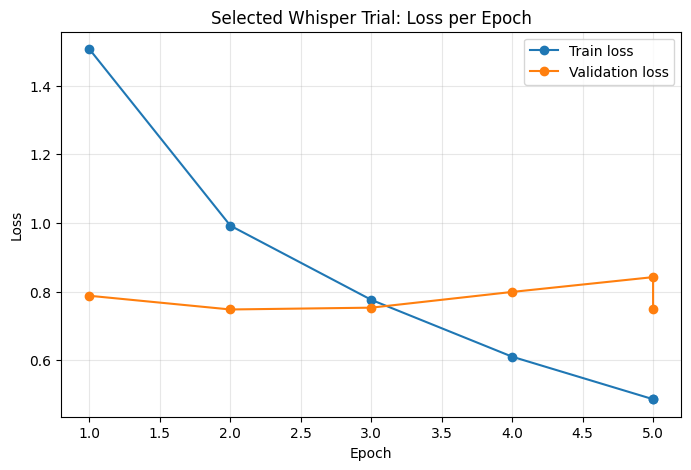

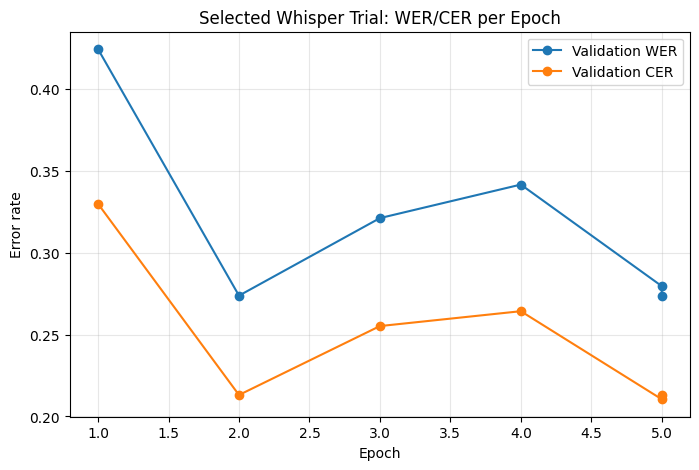

In [ ]:
selected_epoch_metrics_path = Path(best_trial_dir).parent / "epoch_metrics.csv"

if selected_epoch_metrics_path.exists():
    epoch_history = pd.read_csv(selected_epoch_metrics_path)
    display(epoch_history)

    plt.figure(figsize=(8, 5))
    plt.plot(epoch_history["epoch"], epoch_history["train_loss"], marker="o", label="Train loss")
    plt.plot(epoch_history["epoch"], epoch_history["eval_loss"], marker="o", label="Validation loss")
    plt.xlabel("Epoch")
    plt.ylabel("Loss")
    plt.title("Selected Whisper Trial: Loss per Epoch")
    plt.legend()
    plt.grid(alpha=0.3)
    plt.show()

    plt.figure(figsize=(8, 5))
    plt.plot(epoch_history["epoch"], epoch_history["eval_wer"], marker="o", label="Validation WER")
    plt.plot(epoch_history["epoch"], epoch_history["eval_cer"], marker="o", label="Validation CER")
    plt.xlabel("Epoch")
    plt.ylabel("Error rate")
    plt.title("Selected Whisper Trial: WER/CER per Epoch")
    plt.legend()
    plt.grid(alpha=0.3)
    plt.show()


## 13. Final held-out test inference on the complete test set

In [ ]:
def final_whisper_predictions(dataset, source_frame, model, processor):
    rows = []
    model.eval()

    progress = tqdm(
        range(len(dataset)),
        desc="Fine-tuned Whisper test inference",
        unit="utterance",
        dynamic_ncols=True,
    )

    for i in progress:
        sample = dataset[i]
        audio = load_audio_16k(sample["audio"])

        inputs = processor(
            audio["array"],
            sampling_rate=audio["sampling_rate"],
            return_tensors="pt",
        ).input_features.to(device=device, dtype=model.dtype)

        with torch.no_grad():
            pred_ids = model.generate(
                inputs,
                max_length=GENERATION_MAX_LENGTH,
                language="en",
                task="transcribe",
            )

        prediction = processor.batch_decode(
            pred_ids,
            skip_special_tokens=True,
            clean_up_tokenization_spaces=False,
        )[0]

        source_row = source_frame.iloc[i].copy()
        row = source_row.to_dict()
        row["prediction"] = normalize_text(prediction)
        row["reference"] = normalize_text(source_row["pidgin_transcription"])
        rows.append(row)

        if (i + 1) % 50 == 0:
            partial = pd.DataFrame(rows)
            progress.set_postfix(
                WER=f"{wer(partial.reference.tolist(), partial.prediction.tolist()):.4f}"
            )

    predictions = pd.DataFrame(rows)
    predictions["wer"] = predictions.apply(
        lambda row: wer(row["reference"], row["prediction"]), axis=1
    )
    predictions["cer"] = predictions.apply(
        lambda row: cer(row["reference"], row["prediction"]), axis=1
    )
    predictions["mwer"] = predictions.apply(
        lambda row: medical_wer(
            [row["prediction"]],
            [row["reference"]],
            [row["medical_terms_pidgen"]],
        ),
        axis=1,
    )
    return predictions

if RUN_FINAL_EVALUATION:
    final_processor = WhisperProcessor.from_pretrained(best_trial_dir)
    final_model = WhisperForConditionalGeneration.from_pretrained(best_trial_dir)
    final_model = final_model.to(device)
    final_model.eval()
    final_model.generation_config.language = "en"
    final_model.generation_config.task = "transcribe"
    final_model.generation_config.forced_decoder_ids = None

    final_predictions = final_whisper_predictions(
        test_raw_ds,
        test_df,
        final_model,
        final_processor,
    )

    final_dir = OUTPUT_ROOT / "final_test"
    final_dir.mkdir(parents=True, exist_ok=True)

    final_predictions.to_csv(
        final_dir / "whisper_finetuned_predictions.csv",
        index=False,
        encoding="utf-8-sig",
    )

    final_metrics = {
        "model": "Whisper-large-v3",
        "setting": "fine_tuned",
        "prompt_mode": "english",
        **compute_overall_metrics(final_predictions),
    }

    pd.DataFrame([final_metrics]).to_csv(
        final_dir / "overall_metrics.csv",
        index=False,
    )

    display(pd.DataFrame([final_metrics]))


Loading weights:   0%|          | 0/1259 [00:00<?, ?it/s]

Fine-tuned Whisper test inference:   0%|          | 0/2245 [00:00<?, ?utterance/s]

,model,setting,prompt_mode,wer,cer,mwer,num_samples,medical_precision,medical_recall,medical_f1,medical_accuracy,medical_evaluated_samples,medical_tp,medical_fp,medical_fn
0,Whisper-large-v3,fine_tuned,english,0.221887,0.175604,0.26957,2245,0.995375,0.774662,0.871257,0.330627,2217,13342,62,3881


## 14. Medical-bearing subset, speaker-level, and code-switch-stratified evaluation

In [ ]:
if RUN_FINAL_EVALUATION:
    # Medical-bearing subset is reported separately.
    final_predictions["reference_medical_term_count"] = final_predictions.apply(
        lambda row: len(reference_medical_terms(row["reference"], row["medical_terms_pidgen"])),
        axis=1,
    )
    medical_subset = final_predictions[
        final_predictions["reference_medical_term_count"] > 0
    ].copy()

    medical_subset_metrics = {
        "model": "Whisper-large-v3",
        "setting": "fine_tuned_medical_bearing_subset",
        **compute_overall_metrics(medical_subset),
    }

    pd.DataFrame([medical_subset_metrics]).to_csv(
        final_dir / "medical_bearing_subset_metrics.csv",
        index=False,
    )
    medical_subset.to_csv(
        final_dir / "medical_bearing_subset_predictions.csv",
        index=False,
        encoding="utf-8-sig",
    )

    # Held-out speaker results.
    speaker_rows = []
    for speaker_id, group in final_predictions.groupby("speaker_id"):
        speaker_rows.append({
            "model": "Whisper-large-v3",
            "speaker_id": speaker_id,
            **compute_overall_metrics(group),
        })

    speaker_metrics = pd.DataFrame(speaker_rows)
    speaker_metrics.to_csv(
        final_dir / "speaker_level_metrics.csv",
        index=False,
    )

    print("Medical-bearing subset:")
    display(pd.DataFrame([medical_subset_metrics]))

    print("Speaker-level metrics:")
    display(speaker_metrics)

    # Code-switch stratification requested by reviewers.
    if "code_switch_category" in final_predictions.columns:
        code_switch_rows = []
        for category, group in final_predictions.groupby("code_switch_category"):
            if len(group) == 0:
                continue
            code_switch_rows.append({
                "model": "Whisper-large-v3",
                "code_switch_category": category,
                **compute_overall_metrics(group),
            })

        code_switch_metrics = pd.DataFrame(code_switch_rows)
        code_switch_metrics.to_csv(
            final_dir / "code_switch_stratified_metrics.csv",
            index=False,
        )

        print("Code-switch-stratified metrics:")
        display(code_switch_metrics)


Medical-bearing subset:


,model,setting,wer,cer,mwer,num_samples,medical_precision,medical_recall,medical_f1,medical_accuracy,medical_evaluated_samples,medical_tp,medical_fp,medical_fn
0,Whisper-large-v3,fine_tuned_medical_bearing_subset,0.222195,0.175807,0.26957,2217,0.995375,0.774662,0.871257,0.330627,2217,13342,62,3881


Speaker-level metrics:


,model,speaker_id,wer,cer,mwer,num_samples,medical_precision,medical_recall,medical_f1,medical_accuracy,medical_evaluated_samples,medical_tp,medical_fp,medical_fn
0,Whisper-large-v3,Speaker_1,0.298292,0.239416,0.338034,499,0.993473,0.721498,0.835919,0.248996,498,3044,20,1175
1,Whisper-large-v3,Speaker_10,0.181022,0.143147,0.208351,496,0.997921,0.825756,0.903712,0.372470,494,3360,7,709
2,Whisper-large-v3,Speaker_17,0.259519,0.209727,0.306561,251,0.998771,0.722667,0.838577,0.418103,232,813,1,312
3,Whisper-large-v3,Speaker_4,0.229888,0.170980,0.294365,500,0.993234,0.741040,0.848800,0.243461,497,2936,20,1026
4,Whisper-large-v3,Speaker_6,0.152002,0.125185,0.219145,499,0.995629,0.828742,0.904553,0.417339,496,3189,14,659


## 15. Reviewer-ready experiment summary

In [ ]:
summary = {
    "model": MODEL_NAME,
    "seed": SEED,
    "split_manifest": str(SPLIT_MANIFEST_PATH),
    "train_speakers": sorted(train_speakers),
    "validation_speakers": sorted(val_speakers),
    "test_speakers": sorted(test_speakers),
    "train_samples": len(train_df),
    "validation_samples": len(val_df),
    "test_samples": len(test_df),
    "effective_batch_size": (
        PER_DEVICE_TRAIN_BATCH_SIZE * GRADIENT_ACCUMULATION_STEPS
    ),
    "hyperparameter_trials": HYPERPARAMETER_TRIALS,
    "selected_model_path": str(best_trial_dir),
    "selection_metric": "validation_wer",
    "validated_lexicon_used": VALIDATED_LEXICON_PATH is not None,
    "gpu": torch.cuda.get_device_name(0) if torch.cuda.is_available() else "CPU",
}

with open(OUTPUT_ROOT / "experiment_summary.json", "w") as f:
    json.dump(summary, f, indent=2)

print(json.dumps(summary, indent=2))
print("\nPrimary aligned prediction file:")
print(OUTPUT_ROOT / "final_test" / "whisper_finetuned_predictions.csv")


{
  "model": "openai/whisper-large-v3",
  "seed": 42,
  "split_manifest": "/content/drive/MyDrive/Brock_University/pidgindataset2026October/PidginMed-ASR/shared_split_manifest.csv",
  "train_speakers": [
    "Speaker_11",
    "Speaker_12",
    "Speaker_13",
    "Speaker_15",
    "Speaker_16",
    "Speaker_18",
    "Speaker_19",
    "Speaker_20",
    "Speaker_3",
    "Speaker_5",
    "Speaker_7",
    "Speaker_8",
    "Speaker_9"
  ],
  "validation_speakers": [
    "Speaker_14",
    "Speaker_2",
    "Speaker_21"
  ],
  "test_speakers": [
    "Speaker_1",
    "Speaker_10",
    "Speaker_17",
    "Speaker_4",
    "Speaker_6"
  ],
  "train_samples": 6474,
  "validation_samples": 1499,
  "test_samples": 2245,
  "effective_batch_size": 32,
  "hyperparameter_trials": [
    {
      "learning_rate": 1e-05,
      "epochs": 5,
      "weight_decay": 0.0
    }
  ],
  "selected_model_path": "/content/drive/MyDrive/Brock_University/pidgindataset2026October/PidginMed-ASR/whisper/hyperparameter_search/tr